# Hands-on 2, Chapter 2: A Repetition-Code Memory Experiment

You write the core of a repetition-code memory experiment: one syndrome round, and the detectors that compare rounds.
The noise annotations and the rest of the experiment are given, and the last cell computes logical error rates with `DetectorExperiment`.

* Three exercises, about 20 minutes. Every exercise ends with a check cell that prints ✅ or ❌ with a hint.
* Stuck? The solutions are in `ch2_repetition_code_solutions.ipynb`.
* More detail, including runs on IQM hardware: the [DetectorExperiment tutorial](https://docs.iqm.tech/iqm-client/user_guide_qrisp/detector_experiment_demo.html) in the IQM client documentation.

In [1]:
# %pip install qrisp "iqm-client[qrisp]"  # uncomment on Colab

import numpy as np
import jax
from IPython.display import SVG, display
from qrisp import QuantumArray, QuantumBool, x, cx, measure, reset, parity, jaspify
from qrisp.misc.stim_tools import stim_noise
from iqm.qrisp_iqm import DetectorExperiment

D = 4  # code distance used in the exercises


def check(test, hint, success="Correct!"):
    """Run test() and print ✅ on success or ❌ with a hint."""
    try:
        ok = bool(test())
    except NotImplementedError:
        ok, hint = False, "not implemented yet. " + hint
    except Exception as e:
        ok, hint = False, f"{type(e).__name__}: {e}. " + hint
    print(f"✅ {success}" if ok else f"❌ Not yet: {hint}")

## Exercise 2.1: Parity warm-up (5 min)

The repetition code stores one logical bit in $d$ data bits: $|1_L\rangle$ is `1111` for $d = 4$.
The parities of neighbouring bits (XOR) show *where* a bit flipped without revealing the stored value.
Write `syndrome(bits)`, which returns the $d - 1$ neighbour parities of a 0/1 array.
Then find two different two-flip corruptions of `1111` with the same syndrome.

**Predict first:** which syndrome does a flip of `data[0]` give for $d = 4$?

`(1, 0, 0)`. An end bit takes part in one check, an inner bit in two.

In [2]:
def syndrome(bits: np.ndarray) -> np.ndarray:
    """Neighbour parities bits[i] XOR bits[i+1] of a 0/1 array."""
    bits = np.asarray(bits)
    return bits[:-1] ^ bits[1:]


# Two corruptions of 1111 by two bit flips each, at different positions, with the same syndrome
ambiguous: tuple[np.ndarray, np.ndarray] | None = (np.array([1, 0, 0, 1]), np.array([0, 1, 1, 0]))

In [3]:
check(lambda: list(syndrome([1, 0, 1, 1])) == [1, 1, 0] and list(syndrome([1, 1, 1, 1])) == [0, 0, 0],
      "syndrome([1, 0, 1, 1]) should be [1, 1, 0]: XOR every bit with its right neighbour.")


def is_ambiguous(pair):
    a, b = (np.asarray(v) for v in pair)
    flips = lambda v: set(np.flatnonzero(v != 1))
    return (len(flips(a)) == 2 and len(flips(b)) == 2 and flips(a) != flips(b)
            and list(syndrome(a)) == list(syndrome(b)))


check(lambda: is_ambiguous(ambiguous),
      "Both arrays need exactly two 0s (flips of 1111) at different positions and the same syndrome. "
      "Compare flipping the two inner bits with flipping the two end bits.")

✅ Correct!
✅ Correct!


## Exercise 2.2: One noiseless syndrome round (8 min)

On the device, ancilla qubits compute the parities. Data and ancilla qubits alternate on a chain:
`qubits = QuantumArray(shape=(2*d - 1,), qtype=QuantumBool())`, `data = qubits[::2]`, `ancilla = qubits[1::2]`.
Write `syndrome_round(data, ancilla)`: reset the ancillas, apply CX layer 1 (`data[i]` to `ancilla[i]`) and CX layer 2 (`data[i+1]` to `ancilla[i]`), then return `measure(ancilla)`, a JAX bool array.

**Predict first:** after `x(data)` and an extra `x(data[1])`, which ancillas read 1?

`ancilla[0]` and `ancilla[1]`: the syndrome `(1, 1, 0)`, as in Exercise 2.1.

In [4]:
def syndrome_round(data: QuantumArray, ancilla: QuantumArray) -> jax.Array:
    reset(ancilla)
    for i in range(ancilla.size):         # CX layer 1
        cx(data[i], ancilla[i])
    for i in range(ancilla.size):         # CX layer 2
        cx(data[i + 1], ancilla[i])
    return measure(ancilla)               # JAX bool array


predicted_syndrome: list[int] | None = [1, 1, 0]

In [5]:
def one_round(flip=None):
    qubits = QuantumArray(shape=(2 * D - 1,), qtype=QuantumBool())
    data, ancilla = qubits[::2], qubits[1::2]
    x(data)                       # logical |1_L>
    if flip is not None:          # a static if: it decides which program is built
        x(data[flip])
    return syndrome_round(data, ancilla)


def run(flip=None):
    return [int(b) for b in jaspify(lambda: one_round(flip))()]


check(lambda: run() == [0, 0, 0],
      "With x(data) and no error, every ancilla should read 0. Did you reset and apply both CX layers?")
check(lambda: run(1) == predicted_syndrome == [1, 1, 0],
      "Compare run(1) with your prediction. A flip on data[1] changes the checks on both of its sides.")

✅ Correct!
✅ Correct!


## Given: the same round with noise annotations

Real qubits make errors, and the decoder has to know **where** errors may happen and **how likely** they are.
`stim_noise(name, p, *qubits)` marks such a place. It adds no gates: on hardware the real noise acts instead.
From these annotations Qrisp derives the decoder's *detector error model*.

The noisy round below is your round from Exercise 2.2 plus four kinds of annotations:

| Annotation | Where | Models |
|---|---|---|
| `X_ERROR` on the ancillas | after the reset | a faulty reset |
| `DEPOLARIZE1` on the data | after the reset | data qubits picking up errors while they wait |
| `DEPOLARIZE2` on both qubits | after every CX (`noisy_cx`) | a faulty two-qubit gate |
| `X_ERROR` on the ancillas | before the measurement | a faulty readout |

`p` is the error probability of each annotation. Run the cell; the Stim timeline below shows one noisy round for $d = 3$.

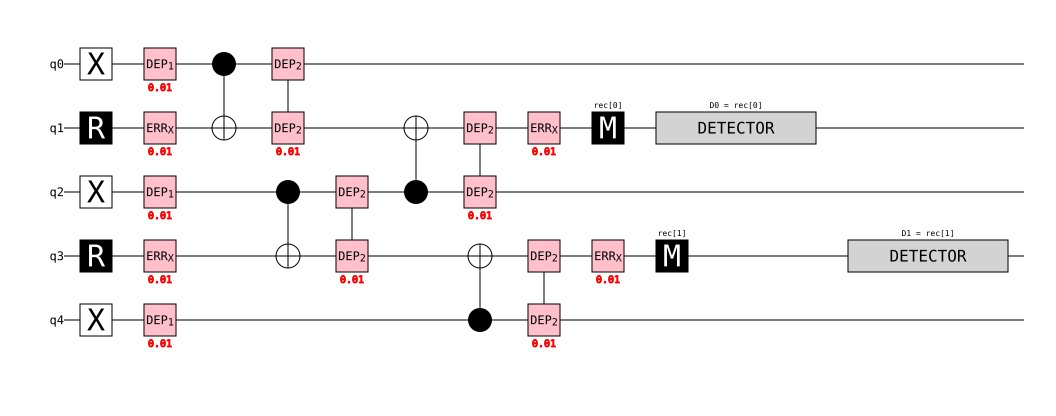

In [6]:
def noisy_cx(c: QuantumBool, t: QuantumBool, p: float) -> None:
    cx(c, t)
    stim_noise("DEPOLARIZE2", p, c, t)    # faulty CX


def syndrome_round(data: QuantumArray, ancilla: QuantumArray, p: float = 0.0) -> jax.Array:
    reset(ancilla)
    stim_noise("X_ERROR", p, ancilla)     # faulty reset
    stim_noise("DEPOLARIZE1", p, data)    # idling data
    for i in range(ancilla.size):         # CX layer 1
        noisy_cx(data[i], ancilla[i], p)
    for i in range(ancilla.size):         # CX layer 2
        noisy_cx(data[i + 1], ancilla[i], p)
    stim_noise("X_ERROR", p, ancilla)     # faulty readout
    return measure(ancilla)


def one_noisy_round(d, p):
    qubits = QuantumArray(shape=(2 * d - 1,), qtype=QuantumBool())
    data, ancilla = qubits[::2], qubits[1::2]
    x(data)
    return list(parity(syndrome_round(data, ancilla, p), expectation=0)), []


circuit = DetectorExperiment(one_noisy_round).to_stim(3, 0.01)
display(SVG(str(circuit.diagram("timeline-svg"))))

## Exercise 2.3: Detectors across rounds (6 min)

Errors keep happening, so the syndrome is measured in every round.
A **detector** compares a syndrome bit with the round before: the first round with 0 (fresh ancillas), every later round with the previous one.
`parity(new, old, expectation=0)` does this element-wise on two measured JAX arrays.

Write `multi_round(data, ancilla, rounds, p)`. It returns `(dets, last)`: the list of all detectors and the last syndrome.
Return the detectors as a **flat list**: `dets = list(parity(...))` and `dets += list(parity(...))`.

**Predict first:** how many detectors does `multi_round` produce for $d = 4$ and 3 rounds?

$3 \cdot (d - 1) = 9$: one per ancilla and round.

In [7]:
def multi_round(data: QuantumArray, ancilla: QuantumArray, rounds: int,
                p: float = 0.0) -> tuple[list, jax.Array]:
    old = syndrome_round(data, ancilla, p)
    dets = list(parity(old, expectation=0))
    for r in range(1, rounds):
        new = syndrome_round(data, ancilla, p)
        dets += list(parity(new, old, expectation=0))
        old = new
    return dets, old


predicted_num_detectors: int | None = 9

In [8]:
def clean_run(rounds):
    qubits = QuantumArray(shape=(2 * D - 1,), qtype=QuantumBool())
    data, ancilla = qubits[::2], qubits[1::2]
    x(data)
    dets, last = multi_round(data, ancilla, rounds)
    return dets


def clean_detectors_ok():
    dets = jaspify(lambda: clean_run(3))()   # raises if a detector fires
    return (isinstance(dets, list) and len(dets) == predicted_num_detectors == 9
            and all(np.ndim(v) == 0 for v in dets) and not any(bool(v) for v in dets))


check(clean_detectors_ok,
      "Expected a flat list of 3 * (d - 1) = 9 detectors, all 0 in a noiseless run. "
      "Use list(parity(...)) and compare every round after the first with the previous one.")

✅ Correct!


## Given: the experiment and its logical error rate

After the last round the data qubits are measured. The final detectors compare them with the last syndrome,
and the last data qubit is the **observable**, the logical value. `@DetectorExperiment` turns the function into an experiment:
`compute_LER` traces it, builds the detector error model from the annotations, samples with Stim, decodes with PyMatching and returns the logical error rate.
Run the cell: larger codes should give fewer logical errors at $p = 0.01$.

To go further (threshold, more rounds, runs on IQM hardware), follow the [DetectorExperiment tutorial](https://docs.iqm.tech/iqm-client/user_guide_qrisp/detector_experiment_demo.html).
A free IQM Resonance account (resonance.iqm.tech/signup) is enough for the hardware part.

In [9]:
@DetectorExperiment
def rep_code(d: int, rounds: int, p: float):
    qubits = QuantumArray(shape=(2 * d - 1,), qtype=QuantumBool())
    data, ancilla = qubits[::2], qubits[1::2]
    x(data)                                  # logical |1_L>
    dets, last = multi_round(data, ancilla, rounds, p)
    final = measure(data)
    for i in range(d - 1):                   # final detectors
        dets.append(parity(final[i], last[i], final[i + 1], expectation=0))
    obs = parity(final[-1], expectation=1, observable=True)
    return dets, [obs]


try:
    for d in (3, 5, 7):
        print(f"d = {d}: logical error rate {rep_code.compute_LER(d, d, 0.01, shots=100_000):.5f}")
except Exception as e:
    print(f"Complete Exercise 2.3 first ({type(e).__name__}).")

d = 3: logical error rate 0.00379
d = 5: logical error rate 0.00101
d = 7: logical error rate 0.00021


## What you built

* A syndrome round on a `QuantumArray` of `QuantumBool`, checked with `jaspify`.
* Detectors with `parity` that compare rounds.
* Together with the given noise annotations: a `DetectorExperiment` that returns logical error rates.

Questions: [GitHub](https://github.com/eclipse-qrisp/Qrisp), Discord, [qrisp.eu](https://qrisp.eu).